In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set plot style
sns.set_theme(style='whitegrid')
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load training and test datasets
train_df = pd.read_csv('Train.csv')
test_df = pd.read_csv('Test.csv')

print(f"Training dataset shape: {train_df.shape}")
print(f"Testing dataset shape:  {test_df.shape}")

print("\nMissing values in Train set:")
print(train_df.isnull().sum())

train_df.head()

Training dataset shape: (1600, 6)
Testing dataset shape:  (400, 5)

Missing values in Train set:
feature_1    0
feature_2    0
feature_3    0
feature_4    0
feature_5    0
target       0
dtype: int64


,feature_1,feature_2,feature_3,feature_4,feature_5,target
0,0.293416,-0.945599,-0.421105,0.406816,0.525662,-82.154667
1,-0.836084,-0.189228,-0.776403,-1.053831,0.597997,-48.897960
2,0.236425,0.132836,-0.147723,0.699854,-0.187364,77.270371
3,0.175312,0.143194,-0.581111,-0.122107,-1.292168,-2.988581
4,-1.693011,0.542712,-2.798729,-0.686723,1.244077,-37.596722


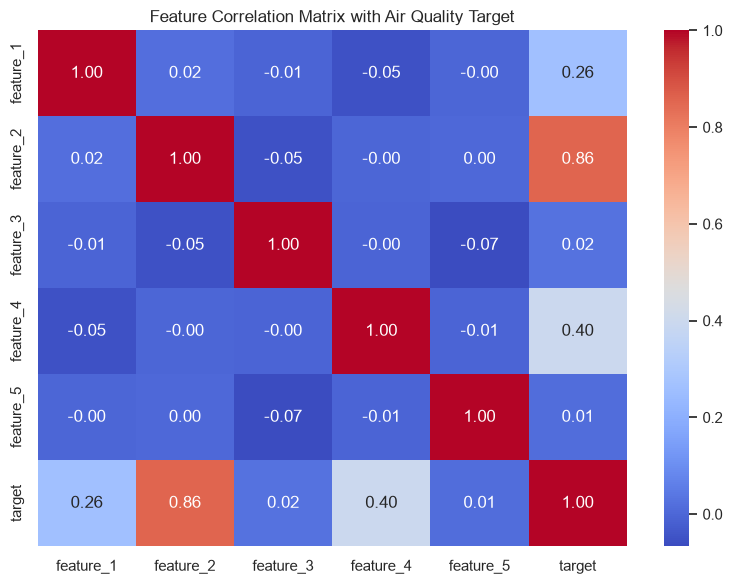

Correlation ranking with target:
target       1.000000
feature_2    0.855356
feature_4    0.396420
feature_1    0.260274
feature_3    0.024866
feature_5    0.014760
Name: target, dtype: float64


In [3]:
# Correlation matrix analysis
plt.figure(figsize=(8, 6))
sns.heatmap(train_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.title('Feature Correlation Matrix with Air Quality Target', fontsize=12)
plt.tight_layout()
plt.show()

# Print ranked feature correlation with target
print("Correlation ranking with target:")
print(train_df.corr()['target'].sort_values(ascending=False))

In [4]:
features = ['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5']

X_train = train_df[features]
y_train = train_df['target']

X_test = test_df[features]

# Train multiple linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Model Intercept (Bias): {model.intercept_:.4f}")
print("Model Coefficients:")
for feat, coef in zip(features, model.coef_):
    print(f"  {feat}: {coef:.4f}")

Model Intercept (Bias): 4.9910
Model Coefficients:
  feature_1: 29.6819
  feature_2: 92.6625
  feature_3: 8.2806
  feature_4: 44.7677
  feature_5: 2.5192


In [5]:
train_predictions = model.predict(X_train)

r2 = r2_score(y_train, train_predictions)
rmse = np.sqrt(mean_squared_error(y_train, train_predictions))

print(f"R-squared (R2) Score: {r2:.4f} ({r2 * 100:.2f}% variance explained)")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

R-squared (R2) Score: 0.9661 (96.61% variance explained)
Root Mean Squared Error (RMSE): 20.3851


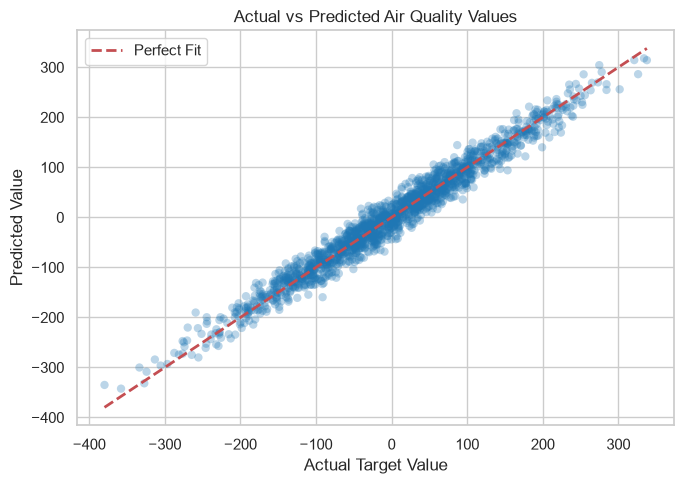

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(y_train, train_predictions, alpha=0.3, color='#1f77b4', edgecolors='none')
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2, label='Perfect Fit')
plt.title('Actual vs Predicted Air Quality Values', fontsize=12)
plt.xlabel('Actual Target Value')
plt.ylabel('Predicted Value')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Generate predictions on unseen test dataset
test_predictions = model.predict(X_test)

submission_df = pd.DataFrame(test_predictions, columns=['target'])
submission_df.to_csv('Test_Predictions.csv', index=False)

print("Predictions successfully saved to 'Test_Predictions.csv'.")
print("\nFirst 5 test predictions:")
print(submission_df.head())

Predictions successfully saved to 'Test_Predictions.csv'.

First 5 test predictions:
       target
0  114.583689
1  118.012815
2  -21.739852
3  -43.936899
4  -95.914898
